# Llama 3.2-3B Compound Compression Energy Ablation - v5 Final

**CSE407 Green Computing | Google Colab free-tier T4 | 10 Hz NVML monitoring**

| Config | Weights | Eviction | KV quantization |
|---|---|---|---|
| C0 | FP16 | None | None |
| C1 | AWQ 4-bit | None | None |
| C2 | AWQ 4-bit | PyramidKV | None |
| C3 | AWQ 4-bit | None | TurboQuant 4-bit codebook |
| C4 | AWQ 4-bit | PyramidKV | TurboQuant 4-bit codebook |

Contexts are **1024, 2048, and 4096**. The 8192 condition is excluded because it
previously exceeded the free-tier T4 memory limit.

### Correctness boundary

- One minimal `LlamaAttention.forward` wrapper is used only by C2 and C4.
- Prefill attends to full K/V, then PyramidKV selects K/V per KV head.
- C4 sends only selected K/V through `TurboQuantCache.update`; evicted tokens never
  enter TurboQuant's internal state.
- TurboQuant is the independent PyPI reference implementation, not a fused INT4
  attention kernel. Version 0.2.0 uses one uint8 index per coordinate at every
  requested bit width and retains dequantized working tensors. The notebook reports
  codebook precision, package payload bytes, and total live cache bytes separately.
- Energy uses a fixed 64-token teacher-forced decode trace. NIAH quality is measured
  separately with natural greedy generation. Retrieval and exact-format compliance
  are scored independently.
- Sensitivity runs add PyramidKV budgets 512/1536 and TurboQuant bits 2/3 at 4096;
  the core C2 budget 1024 and C3 bit width 4 provide the corresponding baselines.

## 1. Install

Run once, restart the Colab session, then continue.

In [ ]:
%pip install -q "autoawq==0.2.9" "gptqmodel==7.1.0" "turboquant==0.2.0"
%pip install -q "transformers==5.12.1" accelerate nvidia-ml-py pandas matplotlib scipy
print("Restart the Colab session: Runtime -> Restart session")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.3/74.3 kB 5.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 17.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 6.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.6/130.6 kB 7.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.4/106.4 kB 10.9 MB/s eta 0:00:00
  Installing build

## 2. Imports, paths, and configuration

In [ ]:
import gc, hashlib, importlib.metadata, json, os, random, re, threading, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import torch
import torch.nn.functional as F

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import pynvml
import transformers
import turboquant
from transformers import AutoModelForCausalLM, AutoTokenizer, DynamicCache, set_seed
from transformers.models.llama.modeling_llama import (
    LlamaAttention, apply_rotary_pos_emb, eager_attention_forward, repeat_kv,
)
from transformers.modeling_utils import ALL_ATTENTION_FUNCTIONS
from turboquant import TurboQuantCache, TurboQuantMSE

SEED = 407
SCHEMA_VERSION = "v5-final-2026-07-31-1"
SESSION_ID = time.strftime("%Y%m%dT%H%M%S") + "-" + os.urandom(4).hex()
MODEL_FP16 = "unsloth/Llama-3.2-3B-Instruct"
MODEL_AWQ = "casperhansen/llama-3.2-3b-instruct-awq"
MODEL_FP16_REVISION = "006f5dcd1393c3add266de40994ba96225e9689d"
MODEL_AWQ_REVISION = "272b3bde867b606760447deb9a4d2719fbdfd3ae"
CONTEXTS = [1024, 2048, 4096]
DEPTHS = [0.1, 0.5, 0.9]
QUALITY_SEEDS = range(5)
MEASURED_BLOCKS = 5
FIXED_DECODE_TOKENS = 64
QUALITY_MAX_NEW = 32
DEFAULT_AVERAGE_BUDGET = 1024
DEFAULT_TQ_BITS = 4
SENSITIVITY_CONTEXT = 4096
PYRAMID_SENSITIVITY = [512, 1536]
TQ_BIT_SENSITIVITY = [2, 3]
SENSITIVITY_CONDITIONS = [
    {"variant": f"C2-B{budget}", "config": "C2",
     "average_budget": budget, "tq_bits": DEFAULT_TQ_BITS}
    for budget in PYRAMID_SENSITIVITY
] + [
    {"variant": f"C3-TQ{bits}", "config": "C3",
     "average_budget": DEFAULT_AVERAGE_BUDGET, "tq_bits": bits}
    for bits in TQ_BIT_SENSITIVITY
]

# Drive persistence is recommended for free-tier session disconnects.
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = Path("/content/drive/MyDrive/CSE407_llama_v5_final")
else:
    SAVE_DIR = Path("/content/CSE407_llama_v5_final")
SAVE_DIR.mkdir(parents=True, exist_ok=True)
ENERGY_CSV = SAVE_DIR / "v5_final_energy_results.csv"
QUALITY_CSV = SAVE_DIR / "v5_final_quality_results.csv"
SENSITIVITY_ENERGY_CSV = SAVE_DIR / "v5_final_sensitivity_energy_4096.csv"
SENSITIVITY_QUALITY_CSV = SAVE_DIR / "v5_final_sensitivity_quality_4096.csv"
DISTORTION_CSV = SAVE_DIR / "v5_final_turboquant_distortion.csv"
IDLE_JSON = SAVE_DIR / "v5_final_idle_telemetry.json"
POWER_TRACE_DIR = SAVE_DIR / "power_traces"
POWER_TRACE_DIR.mkdir(exist_ok=True)
VALIDATION_JSON = SAVE_DIR / "v5_final_validation.json"

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert torch.cuda.is_available(), "A CUDA GPU is required."

pynvml.nvmlInit()
NVML_HANDLE = pynvml.nvmlDeviceGetHandleByIndex(0)
GPU = torch.cuda.get_device_properties(0)
assert "T4" in GPU.name, f"Expected an NVIDIA T4, found {GPU.name!r}."

def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return "not-installed"

TQ_PACKAGE_DIR = Path(turboquant.__file__).parent
TQ_SOURCE_SHA256 = hashlib.sha256(b"".join(
    path.read_bytes() for path in sorted(TQ_PACKAGE_DIR.glob("*.py"))
)).hexdigest()

ENVIRONMENT = {
    "schema_version": SCHEMA_VERSION,
    "gpu": GPU.name,
    "vram_gb": round(GPU.total_memory / 2**30, 2),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "turboquant": package_version("turboquant"),
    "turboquant_source_sha256": TQ_SOURCE_SHA256,
    "gptqmodel": package_version("gptqmodel"),
    "contexts": CONTEXTS,
    "fixed_decode_tokens": FIXED_DECODE_TOKENS,
    "seed": SEED,
    "cuda_runtime": torch.version.cuda,
    "accelerate": package_version("accelerate"),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": package_version("scipy"),
    "pyramid_sensitivity": PYRAMID_SENSITIVITY,
    "tq_bit_sensitivity": TQ_BIT_SENSITIVITY,
    "sensitivity_context": SENSITIVITY_CONTEXT,
    "sensitivity_conditions": SENSITIVITY_CONDITIONS,
    "model_fp16_revision": MODEL_FP16_REVISION,
    "model_awq_revision": MODEL_AWQ_REVISION,
}
assert ENVIRONMENT["transformers"] == "5.12.1"
assert ENVIRONMENT["turboquant"] == "0.2.0"
assert ENVIRONMENT["gptqmodel"] == "7.1.0"
(SAVE_DIR / "v5_final_environment.json").write_text(json.dumps(
    {**ENVIRONMENT, "session_id": SESSION_ID}, indent=2,
))
print(json.dumps(ENVIRONMENT, indent=2))

Mounted at /content/drive
{
  "schema_version": "v5-final-2026-07-31-1",
  "gpu": "Tesla T4",
  "vram_gb": 14.56,
  "torch": "2.11.0+cu128",
  "transformers": "5.12.1",
  "turboquant": "0.2.0",
  "turboquant_source_sha256": "7358e2778c8de6974b0c7212ae8e3dbe00552a96b2e2df0aa42878f239a4c72a",
  "gptqmodel": "7.1.0",
  "contexts": [
    1024,
    2048,
    4096
  ],
  "fixed_decode_tokens": 64,
  "seed": 407,
  "cuda_runtime": "12.8",
  "accelerate": "1.14.0",
  "numpy": "2.2.6",
  "pandas": "2.2.2",
  "scipy": "1.16.3",
  "pyramid_sensitivity": [
    512,
    1536
  ],
  "tq_bit_sensitivity": [
    2,
    3
  ],
  "sensitivity_context": 4096,
  "sensitivity_conditions": [
    {
      "variant": "C2-B512",
      "config": "C2",
      "average_budget": 512,
      "tq_bits": 4
    },
    {
      "variant": "C2-B1536",
      "config": "C2",
      "average_budget": 1536,
      "tq_bits": 4
    },
    {
      "variant": "C3-TQ2",
      "config": "C3",
      "average_budget": 1024,
      "tq_bi

## 3. Power monitor and small helpers

In [ ]:
def nvml_value(function, *args, default=np.nan):
    try:
        return function(*args)
    except (AttributeError, pynvml.NVMLError):
        return default

def sensor_sample():
    mem = pynvml.nvmlDeviceGetMemoryInfo(NVML_HANDLE)
    return {
        "power_w": float(pynvml.nvmlDeviceGetPowerUsage(NVML_HANDLE) / 1000.0),
        "nvml_used_mb": float(mem.used / 2**20),
        "temperature_c": float(nvml_value(
            pynvml.nvmlDeviceGetTemperature, NVML_HANDLE, pynvml.NVML_TEMPERATURE_GPU,
        )),
    }

def telemetry_snapshot():
    sample = sensor_sample()
    sample.update({
        "sm_clock_mhz": float(nvml_value(
            pynvml.nvmlDeviceGetClockInfo, NVML_HANDLE, pynvml.NVML_CLOCK_SM,
        )),
        "memory_clock_mhz": float(nvml_value(
            pynvml.nvmlDeviceGetClockInfo, NVML_HANDLE, pynvml.NVML_CLOCK_MEM,
        )),
        "power_limit_w": float(nvml_value(
            pynvml.nvmlDeviceGetEnforcedPowerLimit, NVML_HANDLE, default=np.nan,
        )) / 1000.0,
        "throttle_reasons": int(nvml_value(
            pynvml.nvmlDeviceGetCurrentClocksThrottleReasons, NVML_HANDLE, default=0,
        )),
    })
    return sample

class GPUMonitor:
    # Thread-safe 10 Hz sampling with synchronized, ordered endpoints.
    def __init__(self, interval_s=0.1):
        self.interval_s = float(interval_s)
        self.samples = []
        self.running = False
        self.stop_event = threading.Event()
        self.lock = threading.Lock()

    def sample(self, elapsed_s=None):
        row = sensor_sample()
        row["elapsed_s"] = float(
            time.perf_counter() - self.t0 if elapsed_s is None else elapsed_s
        )
        with self.lock:
            self.samples.append(row)

    def poll(self):
        deadline = self.t0 + self.interval_s
        while not self.stop_event.wait(max(0.0, deadline - time.perf_counter())):
            try:
                self.sample()
            except pynvml.NVMLError:
                pass
            deadline += self.interval_s

    def start(self):
        if self.running:
            raise RuntimeError("Monitor is already running.")
        torch.cuda.synchronize()
        self.samples = []
        self.stop_event.clear()
        self.t0 = time.perf_counter()
        self.sample(elapsed_s=0.0)
        self.running = True
        self.thread = threading.Thread(target=self.poll, daemon=True)
        self.thread.start()

    def stop(self):
        if not self.running:
            raise RuntimeError("Monitor is not running.")
        torch.cuda.synchronize()
        self.stop_event.set()
        self.thread.join(timeout=2)
        if self.thread.is_alive():
            raise RuntimeError("Power monitor thread did not terminate.")
        self.sample()
        self.running = False
        with self.lock:
            samples = sorted(self.samples, key=lambda row: row["elapsed_s"])
        if len(samples) < 2:
            raise RuntimeError(f"Only {len(samples)} power samples were captured.")
        t = np.asarray([x["elapsed_s"] for x in samples], dtype=float)
        p = np.asarray([x["power_w"] for x in samples], dtype=float)
        duration = float(t[-1] - t[0])
        assert duration > 0 and np.all(np.diff(t) >= 0) and np.isfinite(p).all()
        energy = float(np.trapezoid(p, t))
        temperatures = [x["temperature_c"] for x in samples if np.isfinite(x["temperature_c"])]
        return {
            "energy_j": energy, "duration_s": duration,
            "avg_power_w": energy / duration, "max_power_w": float(p.max()),
            "nvml_peak_mb": float(max(x["nvml_used_mb"] for x in samples)),
            "max_temperature_c": float(max(temperatures)) if temperatures else np.nan,
            "n_samples": len(samples), "samples": samples,
        }

def measure_idle_telemetry(label, seconds=10.0):
    torch.cuda.synchronize()
    samples, deadline = [], time.perf_counter() + seconds
    while True:
        samples.append(sensor_sample())
        if time.perf_counter() >= deadline:
            break
        time.sleep(0.1)
    powers = np.asarray([x["power_w"] for x in samples])
    temperatures = np.asarray([x["temperature_c"] for x in samples])
    temperatures = temperatures[np.isfinite(temperatures)]
    return {
        "label": label, "seconds": seconds, "samples": len(samples),
        "power_median_w": float(np.median(powers)),
        "power_mean_w": float(powers.mean()), "power_sd_w": float(powers.std(ddof=1)),
        "temperature_median_c": float(np.median(temperatures)) if len(temperatures) else np.nan,
    }

def gpu_memory_snapshot():
    torch.cuda.synchronize()
    mem = pynvml.nvmlDeviceGetMemoryInfo(NVML_HANDLE)
    return {
        "allocated_mb": float(torch.cuda.memory_allocated() / 2**20),
        "reserved_mb": float(torch.cuda.memory_reserved() / 2**20),
        "nvml_used_mb": float(mem.used / 2**20),
    }

def clear_gpu():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

def append_row(path, row):
    frame = pd.DataFrame([row])
    if path.exists():
        frame = pd.concat([pd.read_csv(path), frame], ignore_index=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    frame.to_csv(temporary, index=False)
    os.replace(temporary, path)

def completed_keys(path, columns, fingerprint):
    if not path.exists():
        return set()
    old = pd.read_csv(path)
    missing = {"fingerprint", *columns} - set(old.columns)
    if missing:
        raise RuntimeError(f"{path} is missing columns: {sorted(missing)}")
    if "fingerprint" not in old or not (old["fingerprint"] == fingerprint).all():
        raise RuntimeError(f"{path} belongs to a different experiment. Move or delete it.")
    return set(map(tuple, old[columns].itertuples(index=False, name=None)))

def discard_incomplete_blocks(path, variants):
    if not path.exists():
        return
    frame = pd.read_csv(path)
    subset = frame[frame["variant"].isin(variants)]
    incomplete = []
    expected = set(variants)
    for (context, block), group in subset.groupby(["context", "block"]):
        if set(group.variant) != expected or group.session_id.nunique() != 1:
            incomplete.append((context, block))
    if not incomplete:
        return
    remove = pd.Series(False, index=frame.index)
    for context, block in incomplete:
        remove |= (
            frame.variant.isin(variants) & (frame.context == context) & (frame.block == block)
        )
    print("Discarding incomplete cross-session blocks:", incomplete)
    temporary = path.with_suffix(path.suffix + ".tmp")
    frame[~remove].to_csv(temporary, index=False)
    os.replace(temporary, path)

print("Monitor and helpers ready.")

Monitor and helpers ready.


## 4. Exact-length prompts and fixed decode trace

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_FP16, revision=MODEL_FP16_REVISION, trust_remote_code=True,
)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id

FILLERS = [
    "Computing systems balance latency, memory, power, and reliability. ",
    "Engineers measure workloads carefully before selecting an optimization. ",
    "Long documents contain many details that may or may not affect an answer. ",
    "Energy efficiency depends on both hardware behavior and software design. ",
]

def make_niah_input(ctx_len, depth, seed, return_metadata=False):
    rng = random.Random(SEED + 1000 * seed + ctx_len)
    systems = rng.sample(["ALPHA", "BRAVO", "CHARLIE", "DELTA", "ECHO"], 4)
    codes = [f"{rng.choice('ABCDEFGH')}{rng.randrange(100, 999)}-{rng.choice('KLMNPQ')}{rng.randrange(10, 99)}" for _ in systems]
    target = rng.randrange(len(systems))
    records = [f"System {name} uses activation code {code}." for name, code in zip(systems, codes)]
    needle = "\n" + " ".join(records) + "\n"
    answer = codes[target]

    messages = [
        {"role": "system", "content": "Return only the exact requested activation code."},
        {"role": "user", "content": (
            f"Read the document and report the activation code for System {systems[target]}.\n\n"
            "<DOC>\n{HAYSTACK}\n</DOC>\n\nActivation code:"
        )},
    ]
    template = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    prefix_text, suffix_text = template.split("{HAYSTACK}")
    prefix = tokenizer.encode(prefix_text, add_special_tokens=False)
    suffix = tokenizer.encode(suffix_text, add_special_tokens=False)
    needle_ids = tokenizer.encode(needle, add_special_tokens=False)
    filler_ids = tokenizer.encode("".join(rng.sample(FILLERS, len(FILLERS))), add_special_tokens=False)

    filler_budget = ctx_len - len(prefix) - len(suffix) - len(needle_ids)
    assert filler_budget > 32
    before = int(filler_budget * depth)
    after = filler_budget - before
    before_ids = (filler_ids * (before // len(filler_ids) + 1))[:before]
    after_ids = (filler_ids * (after // len(filler_ids) + 1))[:after]
    ids = prefix + before_ids + needle_ids + after_ids + suffix
    assert len(ids) == ctx_len
    metadata = {
        "needle_start_token": len(prefix) + before,
        "needle_tokens": len(needle_ids),
        "realized_haystack_depth": before / filler_budget,
    }
    result = (torch.tensor([ids], dtype=torch.long), answer)
    return (*result, metadata) if return_metadata else result

TRACE_TEXT = (
    "A controlled decode trace keeps the generated workload identical across every "
    "compression configuration. This prevents early end tokens from changing the amount "
    "of measured work and supports a fair energy comparison. "
) * 4
TRACE_IDS = tokenizer.encode(TRACE_TEXT, add_special_tokens=False)[:FIXED_DECODE_TOKENS]
assert len(TRACE_IDS) == FIXED_DECODE_TOKENS

for ctx in CONTEXTS:
    for depth in DEPTHS:
        ids, _ = make_niah_input(ctx, depth, seed=0)
        assert ids.shape[1] == ctx
print("Prompt lengths and fixed decode trace verified.")

Prompt lengths and fixed decode trace verified.


## 5. Model loaders

In [ ]:
NUM_LAYERS = 28
NUM_Q_HEADS = 24
NUM_KV_HEADS = 8
HEAD_DIM = 128

def validate_model_architecture(model):
    config = model.config
    assert config.model_type == "llama"
    assert config.num_hidden_layers == NUM_LAYERS
    assert config.num_attention_heads == NUM_Q_HEADS
    assert config.num_key_value_heads == NUM_KV_HEADS
    assert getattr(config, "head_dim", config.hidden_size // NUM_Q_HEADS) == HEAD_DIM

def release_previous_model():
    previous = globals().pop("model", None)
    if previous is not None:
        del previous
    clear_gpu()

def load_fp16():
    release_previous_model()
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_FP16, revision=MODEL_FP16_REVISION, dtype=torch.float16, device_map={"": 0},
        attn_implementation="sdpa", trust_remote_code=True,
    ).eval()
    validate_model_architecture(model)
    return model

def load_awq():
    release_previous_model()
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_AWQ, revision=MODEL_AWQ_REVISION, device_map={"": 0},
        attn_implementation="sdpa", trust_remote_code=True,
    ).eval()
    validate_model_architecture(model)
    raw = model.config.quantization_config
    quant = raw.to_dict() if hasattr(raw, "to_dict") else dict(raw)
    assert quant["quant_method"] == "awq"
    assert quant["bits"] == 4 and quant["group_size"] == 128
    return model

def new_cache(use_tq, tq_bits=DEFAULT_TQ_BITS):
    tq_bits = int(tq_bits)
    if use_tq:
        assert tq_bits in {2, 3, 4}
        return TurboQuantCache(bits=tq_bits)
    return DynamicCache()

print("Model loaders ready.")

Model loaders ready.


## 6. Unified cache-compression attention wrapper

C2-C4 share this wrapper so prefill attention always uses full-precision full K/V.
Only after prefill does it store full K/V (C3) or PyramidKV-selected K/V (C2/C4).

In [ ]:
WINDOW = 32
POOL_KERNEL = 5
PYRAMID_BETA = 20
PKV_LOG = []
CAPTURE_KV = False
KV_SAMPLE = {}
ACTIVE_EVICTION = False
_ORIGINAL_LLAMA_FORWARD = LlamaAttention.forward

def build_pyramid_budgets(
    layers=NUM_LAYERS, average_budget=DEFAULT_AVERAGE_BUDGET,
    window=WINDOW, beta=PYRAMID_BETA,
):
    average_budget = int(average_budget)
    assert layers > 1 and average_budget > window and beta > 0
    old_average = average_budget - window
    last = round(old_average / beta)
    first = 2 * old_average - last
    old = np.linspace(first, last, layers).round().astype(int)
    budgets = (old + window).tolist()
    # np.linspace is symmetric, so the rounded schedule retains the requested mean.
    assert len(budgets) == layers and int(np.mean(budgets)) == average_budget
    assert min(budgets) >= window and all(a >= b for a, b in zip(budgets, budgets[1:]))
    return budgets

PYRAMID_BUDGETS = build_pyramid_budgets()
ACTIVE_PYRAMID_BUDGETS = PYRAMID_BUDGETS.copy()

def layer_budget(layer_idx):
    return ACTIVE_PYRAMID_BUDGETS[layer_idx]

def select_pyramid_kv(query_states, key_states, value_states, layer_idx, groups, scaling):
    cache_len = key_states.shape[-2]
    budget = min(layer_budget(layer_idx), cache_len)
    if cache_len <= budget:
        return key_states, value_states

    obs = min(WINDOW, cache_len)
    old_len = cache_len - obs
    old_keep = max(budget - obs, 0)
    if old_keep >= old_len:
        return key_states, value_states

    recent_q = query_states[:, :, -obs:, :]
    repeated_k = repeat_kv(key_states, groups) if groups > 1 else key_states
    scores = torch.matmul(recent_q, repeated_k.transpose(2, 3)) * scaling

    causal = torch.triu(torch.full(
        (obs, obs), float("-inf"), device=scores.device, dtype=scores.dtype,
    ), diagonal=1)
    scores[:, :, :, -obs:] += causal[None, None, :, :]
    probs = F.softmax(scores, dim=-1, dtype=torch.float32)

    # Reduce 24 query heads to 8 KV heads, then score old tokens per KV head.
    prefix_scores = probs[:, :, :, :old_len].sum(dim=-2)
    prefix_scores = prefix_scores.reshape(
        prefix_scores.shape[0], key_states.shape[1], groups, old_len,
    ).mean(dim=2)
    prefix_scores = F.avg_pool1d(
        prefix_scores, kernel_size=POOL_KERNEL, stride=1, padding=POOL_KERNEL // 2,
    )

    topk = prefix_scores.topk(old_keep, dim=-1).indices.sort(dim=-1).values
    gather_idx = topk.unsqueeze(-1).expand(-1, -1, -1, key_states.shape[-1])
    kept_k = key_states[:, :, :old_len, :].gather(2, gather_idx)
    kept_v = value_states[:, :, :old_len, :].gather(2, gather_idx)
    selected_k = torch.cat([kept_k, key_states[:, :, -obs:, :]], dim=2).contiguous()
    selected_v = torch.cat([kept_v, value_states[:, :, -obs:, :]], dim=2).contiguous()

    PKV_LOG.append({
        "layer": int(layer_idx), "before": int(cache_len),
        "after": int(selected_k.shape[-2]), "budget": int(budget),
        "head_selection_differs": bool((topk[:, 1:] != topk[:, :-1]).any().item()),
    })
    return selected_k, selected_v

def pyramid_forward(
    self, hidden_states, position_embeddings=None, attention_mask=None,
    past_key_values=None, **kwargs,
):
    input_shape = hidden_states.shape[:-1]
    hidden_shape = (*input_shape, -1, self.head_dim)
    q = self.q_proj(hidden_states).view(hidden_shape).transpose(1, 2)
    k = self.k_proj(hidden_states).view(hidden_shape).transpose(1, 2)
    v = self.v_proj(hidden_states).view(hidden_shape).transpose(1, 2)
    cos, sin = position_embeddings
    q, k = apply_rotary_pos_emb(q, k, cos, sin)
    q_len = q.shape[-2]
    if CAPTURE_KV and self.layer_idx == 0 and not KV_SAMPLE:
        KV_SAMPLE["key"] = k.detach().reshape(-1, HEAD_DIM)[:1024].float().clone()
        KV_SAMPLE["value"] = v.detach().reshape(-1, HEAD_DIM)[:1024].float().clone()

    # Decode updates before attention. Prefill intentionally does not: full K/V
    # must be used for the current prompt before selected K/V are stored.
    is_prefill = (
        past_key_values is not None
        and past_key_values.get_seq_length(self.layer_idx) == 0
    )
    if past_key_values is not None and not is_prefill:
        k, v = past_key_values.update(k, v, self.layer_idx)

    attention_interface = ALL_ATTENTION_FUNCTIONS.get_interface(
        self.config._attn_implementation, eager_attention_forward,
    )
    attn_output, attn_weights = attention_interface(
        self, q, k, v, attention_mask,
        dropout=0.0, scaling=self.scaling, **kwargs,
    )

    if is_prefill:
        if ACTIVE_EVICTION:
            stored_k, stored_v = select_pyramid_kv(
                q, k, v, self.layer_idx, self.num_key_value_groups, self.scaling,
            )
        else:
            stored_k, stored_v = k, v
        past_key_values.update(stored_k, stored_v, self.layer_idx)

    attn_output = attn_output.reshape(*input_shape, -1).contiguous()
    return self.o_proj(attn_output), attn_weights

def enable_cache_wrapper(use_eviction, average_budget=DEFAULT_AVERAGE_BUDGET):
    global ACTIVE_EVICTION, ACTIVE_PYRAMID_BUDGETS
    PKV_LOG.clear()
    ACTIVE_EVICTION = bool(use_eviction)
    ACTIVE_PYRAMID_BUDGETS = build_pyramid_budgets(average_budget=average_budget)
    LlamaAttention.forward = pyramid_forward
    return ACTIVE_PYRAMID_BUDGETS.copy()

def disable_cache_wrapper():
    global ACTIVE_EVICTION, ACTIVE_PYRAMID_BUDGETS
    LlamaAttention.forward = _ORIGINAL_LLAMA_FORWARD
    ACTIVE_EVICTION = False
    ACTIVE_PYRAMID_BUDGETS = PYRAMID_BUDGETS.copy()

print("Pyramid budgets:", PYRAMID_BUDGETS)
print("Average:", np.mean(PYRAMID_BUDGETS))

FINGERPRINT_DATA = {
    **ENVIRONMENT,
    "model_fp16": MODEL_FP16,
    "model_awq": MODEL_AWQ,
    "depths": DEPTHS,
    "quality_seeds": list(QUALITY_SEEDS),
    "measured_blocks": MEASURED_BLOCKS,
    "quality_max_new": QUALITY_MAX_NEW,
    "window": WINDOW,
    "pool_kernel": POOL_KERNEL,
    "pyramid_budgets": PYRAMID_BUDGETS,
    "pyramid_sensitivity": PYRAMID_SENSITIVITY,
    "tq_bit_sensitivity": TQ_BIT_SENSITIVITY,
    "sensitivity_context": SENSITIVITY_CONTEXT,
    "trace_ids": TRACE_IDS,
}
EXPERIMENT_FINGERPRINT = hashlib.sha256(
    json.dumps(FINGERPRINT_DATA, sort_keys=True).encode()
).hexdigest()[:16]
print("Experiment fingerprint:", EXPERIMENT_FINGERPRINT)

Pyramid budgets: [1966, 1896, 1826, 1757, 1687, 1617, 1547, 1478, 1408, 1338, 1268, 1198, 1129, 1059, 989, 919, 850, 780, 710, 640, 570, 501, 431, 361, 291, 222, 152, 82]
Average: 1024.0
Experiment fingerprint: 8d27af8c9ee94de3


## 7. Energy and quality runners

In [ ]:
CONFIGS = {
    "C0": (False, False),
    "C1": (False, False),
    "C2": (True, False),
    "C3": (False, True),
    "C4": (True, True),
}

def cache_lengths(cache):
    lengths = []
    for layer in cache.layers:
        if hasattr(layer, "_total_len"):
            lengths.append(int(layer._total_len))
        else:
            lengths.append(int(layer.get_seq_length()))
    return lengths

def tensor_storage_bytes(tensors):
    seen, total = set(), 0
    for tensor in tensors:
        if not isinstance(tensor, torch.Tensor) or tensor.numel() == 0:
            continue
        storage = tensor.untyped_storage()
        key = (str(tensor.device), int(storage.data_ptr()), int(storage.nbytes()))
        if key not in seen:
            seen.add(key)
            total += int(storage.nbytes())
    return total

def cache_storage_metrics(cache, prefix):
    all_tensors, indices, payload, materialized = [], [], [], []
    payload_names = {
        "_key_indices", "_value_indices", "_key_norms", "_value_norms",
        "_residual_keys", "_residual_values",
    }
    for layer in cache.layers:
        for name, value in vars(layer).items():
            if isinstance(value, torch.Tensor):
                all_tensors.append(value)
                if name in {"_key_indices", "_value_indices"}:
                    indices.append(value)
                if name in payload_names:
                    payload.append(value)
                if name in {"keys", "values"}:
                    materialized.append(value)
    lengths = cache_lengths(cache)
    retained_fp16 = sum(lengths) * NUM_KV_HEADS * HEAD_DIM * 2 * 2
    live = tensor_storage_bytes(all_tensors)
    package_bytes = 0
    if callable(getattr(cache, "memory_usage_bytes", None)):
        package_bytes = int(cache.memory_usage_bytes().get("total_bytes", 0))
    return {
        f"{prefix}_cache_live_bytes": live,
        f"{prefix}_retained_fp16_bytes": int(retained_fp16),
        f"{prefix}_retained_fp16_to_live_ratio": retained_fp16 / max(live, 1),
        f"{prefix}_tq_index_bytes": tensor_storage_bytes(indices),
        f"{prefix}_tq_payload_bytes": tensor_storage_bytes(payload),
        f"{prefix}_tq_materialized_bytes": tensor_storage_bytes(materialized),
        f"{prefix}_tq_package_reported_bytes": package_bytes,
    }

def validate_cache_path(
    cache, config, ctx, prefill_lengths, decode_tokens,
    average_budget=DEFAULT_AVERAGE_BUDGET, tq_bits=DEFAULT_TQ_BITS,
):
    use_pkv, use_tq = CONFIGS[config]
    assert len(cache.layers) == NUM_LAYERS and len(prefill_lengths) == NUM_LAYERS
    if use_pkv:
        budgets = build_pyramid_budgets(average_budget=average_budget)
        expected = [min(ctx, budget) for budget in budgets]
        evicted = [i for i, budget in enumerate(budgets) if ctx > budget]
        assert prefill_lengths == expected
        assert sorted(row["layer"] for row in PKV_LOG) == evicted
        assert all(
            row["before"] == ctx and row["after"] == expected[row["layer"]]
            and row["budget"] == budgets[row["layer"]] for row in PKV_LOG
        )
    else:
        expected, evicted = [ctx] * NUM_LAYERS, []
        assert prefill_lengths == expected and not PKV_LOG
    final_lengths = cache_lengths(cache)
    assert final_lengths == [length + decode_tokens for length in expected]
    quantized_layers = 0
    if use_tq:
        assert isinstance(cache, TurboQuantCache) and cache.bits == tq_bits
        for layer, total_len in zip(cache.layers, final_lengths):
            assert layer.bits == tq_bits
            quantized_tokens = max(total_len - layer.residual_len, 0)
            residual_tokens = min(total_len, layer.residual_len)
            expected_index_shape = (1, NUM_KV_HEADS, quantized_tokens, HEAD_DIM)
            expected_norm_shape = (1, NUM_KV_HEADS, quantized_tokens, 1)
            if quantized_tokens:
                assert tuple(layer._key_indices.shape) == expected_index_shape
                assert tuple(layer._value_indices.shape) == expected_index_shape
                assert tuple(layer._key_norms.shape) == expected_norm_shape
                assert tuple(layer._value_norms.shape) == expected_norm_shape
            else:
                assert layer._key_indices.numel() == layer._value_indices.numel() == 0
                assert layer._key_norms.numel() == layer._value_norms.numel() == 0
            assert layer._residual_keys.shape[-2] == residual_tokens
            assert layer._residual_values.shape[-2] == residual_tokens
            assert layer.keys.shape[-2] == total_len and layer.values.shape[-2] == total_len
            layer_indices = [layer._key_indices, layer._value_indices]
            present = [x for x in layer_indices if isinstance(x, torch.Tensor) and x.numel()]
            if present:
                quantized_layers += 1
                assert all(x.dtype == torch.uint8 and int(x.max()) < 2**tq_bits for x in present)
        assert quantized_layers == sum(length > 128 for length in final_lengths)
    else:
        assert not isinstance(cache, TurboQuantCache)
    return {
        "structural_pass": True, "quantized_layers": quantized_layers,
        "evicted_layers": len(evicted),
        "cache_min_prefill": min(prefill_lengths), "cache_max_prefill": max(prefill_lengths),
        "cache_min_after": min(final_lengths), "cache_max_after": max(final_lengths),
    }

def save_power_trace(variant, ctx, block, prefill, decode):
    safe_variant = re.sub(r"[^A-Za-z0-9_.-]+", "_", variant)
    path = POWER_TRACE_DIR / f"{safe_variant}_ctx{ctx}_block{block}.json"
    path.write_text(json.dumps({"prefill": prefill, "decode": decode}, indent=2))
    return str(path)

def run_energy(
    model, config, ctx, block, idle, warmup=False,
    average_budget=DEFAULT_AVERAGE_BUDGET, tq_bits=DEFAULT_TQ_BITS, variant=None,
):
    use_pkv, use_tq = CONFIGS[config]
    variant = variant or config
    ids, _ = make_niah_input(ctx, depth=0.5, seed=99)
    ids = ids.to(model.device)
    cache = new_cache(use_tq, tq_bits)
    prefill_monitor = decode_monitor = None
    PKV_LOG.clear()
    if use_pkv or use_tq:
        enable_cache_wrapper(use_pkv, average_budget)

    try:
        clear_gpu()
        telemetry_before = telemetry_snapshot()
        torch.cuda.reset_peak_memory_stats()
        prefill_monitor = GPUMonitor()
        prefill_monitor.start()
        t0 = time.perf_counter()
        with torch.inference_mode():
            out = model(
                input_ids=ids, past_key_values=cache, use_cache=True,
                logits_to_keep=1,
            )
        torch.cuda.synchronize()
        prefill_s = time.perf_counter() - t0
        prefill_power = prefill_monitor.stop()

        before_decode = cache_lengths(cache)
        post_prefill_memory = gpu_memory_snapshot()
        post_prefill_storage = cache_storage_metrics(cache, "post_prefill")
        prefill_peak_mb = torch.cuda.max_memory_allocated() / 2**20
        torch.cuda.reset_peak_memory_stats()
        decode_monitor = GPUMonitor()
        decode_monitor.start()
        t0 = time.perf_counter()
        with torch.inference_mode():
            for step, token_id in enumerate(TRACE_IDS):
                token = torch.tensor([[token_id]], device=model.device)
                position = torch.tensor([[ctx + step]], device=model.device)
                out = model(
                    input_ids=token, position_ids=position,
                    past_key_values=cache, use_cache=True, logits_to_keep=1,
                )
        torch.cuda.synchronize()
        decode_s = time.perf_counter() - t0
        decode_power = decode_monitor.stop()
        after_decode = cache_lengths(cache)
        post_decode_memory = gpu_memory_snapshot()
        post_decode_storage = cache_storage_metrics(cache, "post_decode")
        decode_peak_mb = torch.cuda.max_memory_allocated() / 2**20
        structure = validate_cache_path(
            cache, config, ctx, before_decode, FIXED_DECODE_TOKENS, average_budget, tq_bits,
        )
        telemetry_after = telemetry_snapshot()
        monitored_s = prefill_power["duration_s"] + decode_power["duration_s"]
        total_energy = prefill_power["energy_j"] + decode_power["energy_j"]
        full_history_fp16 = NUM_LAYERS * (ctx + FIXED_DECODE_TOKENS) * NUM_KV_HEADS * HEAD_DIM * 2 * 2
        retained_fp16 = post_decode_storage["post_decode_retained_fp16_bytes"]
        live_cache = post_decode_storage["post_decode_cache_live_bytes"]
        trace_file = "" if warmup else save_power_trace(
            variant, ctx, block, prefill_power["samples"], decode_power["samples"],
        )

        row = {
            "fingerprint": EXPERIMENT_FINGERPRINT,
            "schema_version": SCHEMA_VERSION, "session_id": SESSION_ID,
            "variant": variant, "config": config, "context": ctx,
            "block": block, "warmup": warmup,
            "average_budget": average_budget, "tq_bits": tq_bits,
            "prefill_s": prefill_s, "decode_s": decode_s,
            "prefill_energy_j": prefill_power["energy_j"],
            "decode_energy_j": decode_power["energy_j"],
            "total_energy_j": total_energy,
            "idle_adjusted_energy_j": total_energy - idle["power_median_w"] * monitored_s,
            "decode_j_per_token": decode_power["energy_j"] / FIXED_DECODE_TOKENS,
            "decode_tok_s": FIXED_DECODE_TOKENS / decode_s,
            "avg_power_w": total_energy / monitored_s,
            "max_power_w": max(prefill_power["max_power_w"], decode_power["max_power_w"]),
            "vram_peak_mb": max(prefill_peak_mb, decode_peak_mb),
            "nvml_peak_mb": max(prefill_power["nvml_peak_mb"], decode_power["nvml_peak_mb"]),
            "power_samples": prefill_power["n_samples"] + decode_power["n_samples"],
            "idle_power_w": idle["power_median_w"],
            "temperature_max_c": max(
                prefill_power["max_temperature_c"], decode_power["max_temperature_c"],
            ),
            "temperature_before_c": telemetry_before["temperature_c"],
            "temperature_after_c": telemetry_after["temperature_c"],
            "sm_clock_before_mhz": telemetry_before["sm_clock_mhz"],
            "sm_clock_after_mhz": telemetry_after["sm_clock_mhz"],
            "memory_clock_before_mhz": telemetry_before["memory_clock_mhz"],
            "memory_clock_after_mhz": telemetry_after["memory_clock_mhz"],
            "power_limit_w": telemetry_after["power_limit_w"],
            "throttle_before": telemetry_before["throttle_reasons"],
            "throttle_after": telemetry_after["throttle_reasons"],
            "full_history_fp16_bytes": full_history_fp16,
            "logical_eviction_compression_ratio": full_history_fp16 / max(retained_fp16, 1),
            "realized_live_compression_ratio": full_history_fp16 / max(live_cache, 1),
            "token_retention_ratio": sum(after_decode) / (NUM_LAYERS * (ctx + FIXED_DECODE_TOKENS)),
            "post_prefill_allocated_mb": post_prefill_memory["allocated_mb"],
            "post_prefill_reserved_mb": post_prefill_memory["reserved_mb"],
            "post_prefill_nvml_used_mb": post_prefill_memory["nvml_used_mb"],
            "post_decode_allocated_mb": post_decode_memory["allocated_mb"],
            "post_decode_reserved_mb": post_decode_memory["reserved_mb"],
            "post_decode_nvml_used_mb": post_decode_memory["nvml_used_mb"],
            "trace_file": trace_file,
            **post_prefill_storage, **post_decode_storage, **structure,
        }
        return row
    finally:
        for monitor in [prefill_monitor, decode_monitor]:
            if monitor is not None and monitor.running:
                try:
                    monitor.stop()
                except Exception:
                    monitor.running = False
        if use_pkv or use_tq:
            disable_cache_wrapper()
        PKV_LOG.clear()
        del cache, ids
        clear_gpu()

def score_niah_response(response, answer):
    normalized = response.strip().casefold()
    normalized_answer = answer.casefold()
    retrieval = re.search(
        rf"(?<![a-z0-9]){re.escape(normalized_answer)}(?![a-z0-9])", normalized,
    ) is not None
    exact_format = response.strip() == answer
    assert not exact_format or retrieval
    return retrieval, exact_format

def run_quality(
    model, config, ctx, depth, seed, average_budget=DEFAULT_AVERAGE_BUDGET,
    tq_bits=DEFAULT_TQ_BITS, variant=None,
):
    use_pkv, use_tq = CONFIGS[config]
    variant = variant or config
    ids, answer, prompt_metadata = make_niah_input(ctx, depth, seed, return_metadata=True)
    ids = ids.to(model.device)
    cache = new_cache(use_tq, tq_bits)
    if use_pkv or use_tq:
        enable_cache_wrapper(use_pkv, average_budget)
    else:
        PKV_LOG.clear()
    generated = []

    try:
        with torch.inference_mode():
            out = model(input_ids=ids, past_key_values=cache, use_cache=True, logits_to_keep=1)
            prefill_lengths = cache_lengths(cache)
            next_token = out.logits[:, -1, :].argmax(-1, keepdim=True)
            for step in range(QUALITY_MAX_NEW):
                generated.append(next_token)
                if next_token.item() in np.atleast_1d(tokenizer.eos_token_id):
                    break
                if step == QUALITY_MAX_NEW - 1:
                    break
                position = torch.tensor([[ctx + step]], device=model.device)
                out = model(
                    input_ids=next_token, position_ids=position,
                    past_key_values=cache, use_cache=True, logits_to_keep=1,
                )
                next_token = out.logits[:, -1, :].argmax(-1, keepdim=True)
        output_ids = torch.cat(generated, dim=1)[0].tolist()
        response = tokenizer.decode(output_ids, skip_special_tokens=True)
        retrieval, exact_format = score_niah_response(response, answer)
        decode_tokens = max(0, len(output_ids) - 1)
        structure = validate_cache_path(
            cache, config, ctx, prefill_lengths, decode_tokens, average_budget, tq_bits,
        )
        return {
            "fingerprint": EXPERIMENT_FINGERPRINT,
            "schema_version": SCHEMA_VERSION, "session_id": SESSION_ID,
            "variant": variant, "config": config, "context": ctx,
            "depth": depth, "seed": seed,
            "average_budget": average_budget, "tq_bits": tq_bits,
            "answer": answer,
            "retrieval_correct": retrieval, "format_correct": exact_format,
            "output_tokens": len(output_ids), "response": response,
            "output_token_ids": json.dumps(output_ids), **prompt_metadata,
            **cache_storage_metrics(cache, "quality_final"), **structure,
        }
    finally:
        if use_pkv or use_tq:
            disable_cache_wrapper()
        PKV_LOG.clear()
        del cache, ids
        clear_gpu()

print("Experiment runners ready.")

Experiment runners ready.


## 8. Mandatory validation gates

Run this before either experiment matrix.

In [ ]:
def run_distortion_study(samples):
    rows = []
    for bits in [2, 3, 4]:
        quantizer = TurboQuantMSE(dim=HEAD_DIM, bits=bits, device=str(samples["key"].device))
        for tensor_name in ["key", "value"]:
            original = samples[tensor_name]
            indices, norms = quantizer.quantize(original)
            restored = quantizer.dequantize(indices, norms)
            error = restored.float() - original.float()
            nmse = error.square().sum(-1) / original.float().square().sum(-1).clamp_min(1e-12)
            cosine = F.cosine_similarity(original.float(), restored.float(), dim=-1)
            assert indices.dtype == torch.uint8 and int(indices.max().item()) < 2**bits
            assert torch.isfinite(nmse).all() and torch.isfinite(cosine).all()
            rows.append({
                "fingerprint": EXPERIMENT_FINGERPRINT, "bits": bits,
                "tensor": tensor_name, "vectors": len(original),
                "normalized_mse": float(nmse.mean()),
                "mean_cosine": float(cosine.mean()),
                "physical_index_bytes_per_coordinate": indices.element_size(),
            })
    result = pd.DataFrame(rows)
    result.to_csv(DISTORTION_CSV, index=False)
    return result

model = load_awq()
validation = {"passed": False}
VALIDATION_JSON.unlink(missing_ok=True)
path_results = []
try:
    raw_quant = model.config.quantization_config
    quant = raw_quant.to_dict() if hasattr(raw_quant, "to_dict") else dict(raw_quant)
    assert quant["quant_method"] == "awq"
    assert quant["bits"] == 4 and quant["group_size"] == 128
    ctx = 2048
    cases = [
        ("C2", DEFAULT_AVERAGE_BUDGET, DEFAULT_TQ_BITS),
        ("C3", DEFAULT_AVERAGE_BUDGET, DEFAULT_TQ_BITS),
        ("C4", DEFAULT_AVERAGE_BUDGET, DEFAULT_TQ_BITS),
    ] + [
        (item["config"], item["average_budget"], item["tq_bits"])
        for item in SENSITIVITY_CONDITIONS
    ]
    for config, average_budget, tq_bits in cases:
        use_pkv, use_tq = CONFIGS[config]
        ids, _ = make_niah_input(ctx, 0.5, seed=123)
        ids = ids.to(model.device)
        cache = new_cache(use_tq, tq_bits)
        PKV_LOG.clear()
        if use_pkv or use_tq:
            enable_cache_wrapper(use_pkv, average_budget)
        if config == "C4":
            KV_SAMPLE.clear()
            CAPTURE_KV = True
        with torch.inference_mode():
            out = model(input_ids=ids, past_key_values=cache, use_cache=True, logits_to_keep=1)
        CAPTURE_KV = False
        prefill_lengths = cache_lengths(cache)
        token = out.logits[:, -1, :].argmax(-1, keepdim=True)
        position = torch.tensor([[ctx]], device=model.device)
        with torch.inference_mode():
            model(
                input_ids=token, position_ids=position, past_key_values=cache,
                use_cache=True, logits_to_keep=1,
            )
        result = validate_cache_path(
            cache, config, ctx, prefill_lengths, 1, average_budget, tq_bits,
        )
        result.update({
            "config": config, "average_budget": average_budget, "tq_bits": tq_bits,
            **cache_storage_metrics(cache, "validation"),
        })
        path_results.append(result)
        disable_cache_wrapper()
        del cache, ids, out, token
        clear_gpu()

    assert set(KV_SAMPLE) == {"key", "value"}
    distortion = run_distortion_study(KV_SAMPLE)
    validation = {
        "passed": True, "fingerprint": EXPERIMENT_FINGERPRINT,
        "schema_version": SCHEMA_VERSION,
        "awq": quant, "validated_paths": path_results,
        "distortion_csv": str(DISTORTION_CSV),
        "turboquant_storage_note": (
            "TurboQuant 0.2.0 uses a 2^bits numerical codebook but one uint8 "
            "index per coordinate for bits 2, 3, and 4. Its package memory report "
            "excludes persistent materialized dequantized keys/values and can miss "
            "backing allocation retained by residual slices. Total live cache bytes "
            "deduplicate and include all layer tensor storages; category columns overlap."
        ),
    }
    VALIDATION_JSON.write_text(json.dumps(validation, indent=2))
    print(json.dumps(validation, indent=2))
    display(distortion)
finally:
    CAPTURE_KV = False
    disable_cache_wrapper()
    PKV_LOG.clear()
    for name in ["model", "cache", "ids", "out", "token"]:
        value = globals().pop(name, None)
        if value is not None:
            del value
    clear_gpu()

assert validation["passed"], "Do not run experiments until all gates pass."

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.25GB            

model.safetensors: downloading bytes:           |  0.00B            


INFO  LogBar: headless/AI-agent/notebook/CI environment detected; high-frequency progress bars and animations are disabled.
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.
INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.          
INFO  

┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐
│ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │
└─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘
GPT-QModel   : 7.1.0
Transformers : 5.12.1
Torch        : 2.11.0+cu128
Triton       : 3.6.0
INFO  ExLlamaV2 AWQ: compiling torch.ops JIT e

Loading weights:   0%|          | 0/646 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

INFO  gc.collect() reclaimed 53 objects in 0.376s                              
{
  "passed": true,
  "fingerprint": "8d27af8c9ee94de3",
  "schema_version": "v5-final-2026-07-31-1",
  "awq": {
    "zero_point": true,
    "modules_to_not_convert": null,
    "quant_method": "awq",
    "bits": 4,
    "tokenizer": null,
    "dataset": null,
    "group_size": 128,
    "damp_percent": 0.1,
    "desc_act": false,
    "act_group_aware": true,
    "sym": true,
    "true_sequential": true,
    "format": "gemm",
    "meta": null,
    "backend": "auto",
    "model_seqlen": null,
    "block_name_to_quantize": null,
    "module_name_preceding_first_block": null,
    "batch_size": 1,
    "pad_token_id": null,
    "max_input_length": null,
    "cache_block_outputs": true,
    "modules_in_block_to_quantize": null,
    "version": "gemm"
  },
  "validated_paths": [
    {
      "structural_pass": true,
      "quantized_layers": 0,
      "evicted_layers": 28,
      "cache_min_prefill": 82,
      "cache_max

,fingerprint,bits,tensor,vectors,normalized_mse,mean_cosine,physical_index_bytes_per_coordinate
0,8d27af8c9ee94de3,2,key,1024,0.121250,0.939919,1
1,8d27af8c9ee94de3,2,value,1024,0.131141,0.934995,1
2,8d27af8c9ee94de3,3,key,1024,0.044361,0.978947,1
3,8d27af8c9ee94de3,3,value,1024,0.050641,0.976412,1
4,8d27af8c9ee94de3,4,key,1024,0.016547,0.992201,1
5,8d27af8c9ee94de3,4,value,1024,0.021401,0.989959,1


## 9. Energy matrix and 4096-token sensitivity

Runs 75 measured core trials plus 20 measured sensitivity trials. FP16 and AWQ are
separate model-resident phases (a declared split-plot constraint); context order and
AWQ condition order are randomized. Results and raw 10 Hz traces persist after each run.

In [ ]:
validation = json.loads(VALIDATION_JSON.read_text()) if VALIDATION_JSON.exists() else {}
assert validation.get("passed") and validation.get("fingerprint") == EXPERIMENT_FINGERPRINT
discard_incomplete_blocks(ENERGY_CSV, ["C1", "C2", "C3", "C4"])
done = completed_keys(
    ENERGY_CSV, ["variant", "context", "block"], EXPERIMENT_FINGERPRINT,
)
idle_records = []

# C0 is separate because repeatedly swapping FP16 and AWQ models wastes Colab time.
model = load_fp16()
idle_c0 = measure_idle_telemetry("C0_FP16_model_resident")
idle_records.append(idle_c0)
for ctx in np.random.default_rng(SEED + 100).permutation(CONTEXTS):
    ctx = int(ctx)
    run_energy(model, "C0", ctx, block=-1, idle=idle_c0, warmup=True)
    for block in range(MEASURED_BLOCKS):
        key = ("C0", ctx, block)
        if key in done:
            continue
        row = run_energy(model, "C0", ctx, block, idle=idle_c0, warmup=False)
        append_row(ENERGY_CSV, row)
        print("energy", key, round(row["total_energy_j"], 1), "J")
del model
clear_gpu()

model = load_awq()
idle_awq = measure_idle_telemetry("AWQ_model_resident")
idle_records.append(idle_awq)
for ctx in np.random.default_rng(SEED + 200).permutation(CONTEXTS):
    ctx = int(ctx)
    for config in ["C1", "C2", "C3", "C4"]:
        run_energy(model, config, ctx, block=-1, idle=idle_awq, warmup=True)
    for block in range(MEASURED_BLOCKS):
        order = list(
            np.random.default_rng(SEED + ctx + block).permutation(["C1", "C2", "C3", "C4"])
        )
        for config in order:
            key = (config, ctx, block)
            if key in done:
                continue
            row = run_energy(model, config, ctx, block, idle=idle_awq, warmup=False)
            append_row(ENERGY_CSV, row)
            print("energy", key, round(row["total_energy_j"], 1), "J")

discard_incomplete_blocks(
    SENSITIVITY_ENERGY_CSV, [item["variant"] for item in SENSITIVITY_CONDITIONS],
)
sensitivity_done = completed_keys(
    SENSITIVITY_ENERGY_CSV, ["variant", "context", "block"], EXPERIMENT_FINGERPRINT,
)
for condition in SENSITIVITY_CONDITIONS:
    run_energy(
        model=model, ctx=SENSITIVITY_CONTEXT, block=-1, idle=idle_awq,
        warmup=True, **condition,
    )
for block in range(MEASURED_BLOCKS):
    order = np.random.default_rng(SEED + 50000 + block).permutation(len(SENSITIVITY_CONDITIONS))
    for index in order:
        condition = SENSITIVITY_CONDITIONS[int(index)]
        key = (condition["variant"], SENSITIVITY_CONTEXT, block)
        if key in sensitivity_done:
            continue
        row = run_energy(
            model=model, ctx=SENSITIVITY_CONTEXT, block=block, idle=idle_awq,
            warmup=False, **condition,
        )
        append_row(SENSITIVITY_ENERGY_CSV, row)
        print("sensitivity energy", key, round(row["total_energy_j"], 1), "J")

IDLE_JSON.write_text(json.dumps(idle_records, indent=2))
del model
clear_gpu()
print("Saved:", ENERGY_CSV, SENSITIVITY_ENERGY_CSV)

model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/234 [00:00<?, ?B/s]

energy ('C0', 4096, 0) 690.0 J
energy ('C0', 4096, 1) 696.7 J
energy ('C0', 4096, 2) 707.6 J
energy ('C0', 4096, 3) 710.0 J
energy ('C0', 4096, 4) 701.1 J
energy ('C0', 2048, 0) 340.3 J
energy ('C0', 2048, 1) 344.6 J
energy ('C0', 2048, 2) 341.0 J
energy ('C0', 2048, 3) 348.3 J
energy ('C0', 2048, 4) 352.1 J
energy ('C0', 1024, 0) 254.9 J
energy ('C0', 1024, 1) 235.8 J
energy ('C0', 1024, 2) 233.8 J
energy ('C0', 1024, 3) 261.5 J
energy ('C0', 1024, 4) 234.5 J
INFO  Kernel: Auto-selection: adding candidate `AwqExllamaV2Linear`            
INFO  Kernel: selected -> `AwqExllamaV2Linear`.                                


Loading weights:   0%|          | 0/646 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 5561 objects in 0.288s                            
energy (np.str_('C4'), 1024, 0) 391.8 J
energy (np.str_('C1'), 1024, 0) 239.9 J
energy (np.str_('C3'), 1024, 0) 352.8 J
energy (np.str_('C2'), 1024, 0) 271.8 J
energy (np.str_('C4'), 1024, 1) 344.5 J
energy (np.str_('C1'), 1024, 1) 284.7 J
energy (np.str_('C3'), 1024, 1) 362.8 J
energy (np.str_('C2'), 1024, 1) 237.5 J
energy (np.str_('C1'), 1024, 2) 297.7 J
energy (np.str_('C3'), 1024, 2) 349.4 J
energy (np.str_('C4'), 1024, 2) 365.3 J
energy (np.str_('C2'), 1024, 2) 240.7 J
energy (np.str_('C1'), 1024, 3) 242.2 J
energy (np.str_('C4'), 1024, 3) 380.2 J
energy (np.str_('C3'), 1024, 3) 352.9 J
energy (np.str_('C2'), 1024, 3) 261.4 J
energy (np.str_('C1'), 1024, 4) 279.3 J
energy (np.str_('C2'), 1024, 4) 256.6 J
energy (np.str_('C3'), 1024, 4) 417.1 J
energy (np.str_('C4'), 1024, 4) 342.8 J
energy (np.str_('C4'), 2048, 0) 424.6 J
energy (np.str_('C3'), 2048, 0) 455.7 J
energy (np.str_('C1'), 2048, 0) 308.4 J


## 10. Quality matrix and 4096-token sensitivity

Runs 225 core and 60 sensitivity NIAH cases without power monitoring. Retrieval
correctness is primary; exact-format compliance is reported separately.

In [ ]:
validation = json.loads(VALIDATION_JSON.read_text()) if VALIDATION_JSON.exists() else {}
assert validation.get("passed") and validation.get("fingerprint") == EXPERIMENT_FINGERPRINT
done = completed_keys(
    QUALITY_CSV, ["variant", "context", "depth", "seed"], EXPERIMENT_FINGERPRINT,
)

model = load_fp16()
for ctx in CONTEXTS:
    for depth in DEPTHS:
        for seed in QUALITY_SEEDS:
            key = ("C0", ctx, depth, seed)
            if key not in done:
                row = run_quality(model, "C0", ctx, depth, seed)
                append_row(QUALITY_CSV, row)
                print(
                    "quality", key,
                    "RETRIEVED" if row["retrieval_correct"] else "MISSED",
                    "FORMAT_OK" if row["format_correct"] else "FORMAT_FAIL",
                )
del model
clear_gpu()

model = load_awq()
for ctx in CONTEXTS:
    for depth in DEPTHS:
        for seed in QUALITY_SEEDS:
            order = np.random.default_rng(
                SEED + ctx + int(depth * 100) + 1000 * seed
            ).permutation(["C1", "C2", "C3", "C4"])
            for config in order:
                key = (config, ctx, depth, seed)
                if key not in done:
                    row = run_quality(model, config, ctx, depth, seed)
                    append_row(QUALITY_CSV, row)
                    print(
                        "quality", key,
                        "RETRIEVED" if row["retrieval_correct"] else "MISSED",
                        "FORMAT_OK" if row["format_correct"] else "FORMAT_FAIL",
                    )

sensitivity_done = completed_keys(
    SENSITIVITY_QUALITY_CSV,
    ["variant", "context", "depth", "seed"], EXPERIMENT_FINGERPRINT,
)
for depth in DEPTHS:
    for seed in QUALITY_SEEDS:
        order = np.random.default_rng(
            SEED + 60000 + int(depth * 100) + seed
        ).permutation(len(SENSITIVITY_CONDITIONS))
        for index in order:
            condition = SENSITIVITY_CONDITIONS[int(index)]
            key = (condition["variant"], SENSITIVITY_CONTEXT, depth, seed)
            if key in sensitivity_done:
                continue
            row = run_quality(
                model=model, ctx=SENSITIVITY_CONTEXT, depth=depth, seed=seed,
                **condition,
            )
            append_row(SENSITIVITY_QUALITY_CSV, row)
            print(
                "sensitivity quality", key,
                "RETRIEVED" if row["retrieval_correct"] else "MISSED",
                "FORMAT_OK" if row["format_correct"] else "FORMAT_FAIL",
            )
del model
clear_gpu()
print("Saved:", QUALITY_CSV, SENSITIVITY_QUALITY_CSV)

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


quality ('C0', 1024, 0.1, 0) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.1, 1) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.1, 2) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.1, 3) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.1, 4) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.5, 0) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.5, 1) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.5, 2) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.5, 3) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.5, 4) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.9, 0) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.9, 1) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.9, 2) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.9, 3) RETRIEVED FORMAT_OK
quality ('C0', 1024, 0.9, 4) RETRIEVED FORMAT_OK
quality ('C0', 2048, 0.1, 0) RETRIEVED FORMAT_OK
quality ('C0', 2048, 0.1, 1) RETRIEVED FORMAT_OK
quality ('C0', 2048, 0.1, 2) RETRIEVED FORMAT_OK
quality ('C0', 2048, 0.1, 3) RETRIEVED FORMAT_OK
quality ('C0', 2048, 0.1, 4) RETRIEVED FORMAT_FAIL
quality ('C0', 204

Loading weights:   0%|          | 0/646 [00:00<?, ?it/s]

INFO  gc.collect() reclaimed 5562 objects in 0.302s                            
quality (np.str_('C4'), 1024, 0.1, 0) RETRIEVED FORMAT_OK
quality (np.str_('C3'), 1024, 0.1, 0) RETRIEVED FORMAT_OK
quality (np.str_('C1'), 1024, 0.1, 0) RETRIEVED FORMAT_OK
quality (np.str_('C2'), 1024, 0.1, 0) RETRIEVED FORMAT_OK
quality (np.str_('C2'), 1024, 0.1, 1) RETRIEVED FORMAT_OK
quality (np.str_('C3'), 1024, 0.1, 1) RETRIEVED FORMAT_OK
quality (np.str_('C1'), 1024, 0.1, 1) RETRIEVED FORMAT_OK
quality (np.str_('C4'), 1024, 0.1, 1) RETRIEVED FORMAT_OK
quality (np.str_('C1'), 1024, 0.1, 2) RETRIEVED FORMAT_OK
quality (np.str_('C4'), 1024, 0.1, 2) RETRIEVED FORMAT_OK
quality (np.str_('C3'), 1024, 0.1, 2) RETRIEVED FORMAT_OK
quality (np.str_('C2'), 1024, 0.1, 2) RETRIEVED FORMAT_OK
quality (np.str_('C3'), 1024, 0.1, 3) RETRIEVED FORMAT_OK
quality (np.str_('C1'), 1024, 0.1, 3) RETRIEVED FORMAT_OK
quality (np.str_('C2'), 1024, 0.1, 3) RETRIEVED FORMAT_OK
quality (np.str_('C4'), 1024, 0.1, 3) RETRIEVED FO

## 11. Statistical analysis, sensitivity, and Pareto uncertainty

Core energy summary


,variant,context,total_energy_mean_j,total_energy_sd_j,idle_adjusted_mean_j,prefill_energy_mean_j,decode_energy_mean_j,decode_tok_s,vram_peak_mb,cache_live_mb
0,C0,1024,244.114,13.105,138.601,40.499,203.615,21.093,8810.212,119.000
1,C0,2048,345.265,4.967,196.433,97.026,248.239,17.418,9662.751,231.000
2,C0,4096,701.079,8.123,395.545,323.545,377.534,11.342,12687.829,455.000
3,C1,1024,268.768,26.199,144.133,35.742,233.026,18.239,4942.712,119.000
4,C1,2048,313.807,9.306,173.031,98.537,215.269,20.133,5795.251,231.000
5,C1,4096,631.245,5.055,347.932,319.300,311.946,13.770,8820.330,455.000
6,C2,1024,253.611,14.355,135.895,36.826,216.785,19.306,4919.681,92.289
7,C2,2048,338.740,21.026,183.455,100.088,238.652,17.814,5690.931,119.000
8,C2,4096,529.299,20.016,290.735,317.982,211.317,20.339,8500.009,119.000
9,C3,1024,366.998,28.444,201.613,46.323,320.676,13.492,5099.439,187.250


NIAH retrieval and exact-format accuracy (%)


retrieval_correct  format_correct
variant context depth                                   
C0      1024    0.1                100.0           100.0
                0.5                100.0           100.0
                0.9                100.0           100.0
        2048    0.1                100.0            80.0
                0.5                100.0            80.0
                0.9                100.0            80.0
        4096    0.1                100.0            80.0
                0.5                100.0            80.0
                0.9                100.0           100.0
C1      1024    0.1                100.0           100.0
                0.5                100.0           100.0
                0.9                100.0           100.0
        2048    0.1                100.0            80.0
                0.5                100.0            40.0
                0.9                100.0            40.0
        4096    0.1                100.0           100.0
                0.5                100.0           100.0
                0.9                100.0           100.0
C2      1024    0.1                100.0           100.0
                0.5                100.0           100.0
                0.9                100.0           100.0
        2048    0.1                100.0            80.0
                0.5                100.0            40.0
                0.9                100.0            40.0
        4096    0.1                100.0           100.0
                0.5                100.0            80.0
                0.9                100.0            80.0
C3      1024    0.1                100.0           100.0
                0.5                100.0           100.0
                0.9                100.0           100.0
        2048    0.1                100.0            80.0
                0.5                100.0            40.0
                0.9                100.0            40.0
        4096    0.1                100.0           100.0
                0.5                100.0           100.0
                0.9                100.0           100.0
C4      1024    0.1                100.0           100.0
                0.5                100.0           100.0
                0.9                100.0           100.0
        2048    0.1                100.0            80.0
                0.5                100.0            40.0
                0.9                100.0            40.0
        4096    0.1                100.0           100.0
                0.5                100.0            80.0
                0.9                100.0            80.0

Paired AWQ-path tests at 4096 (C0 is excluded by the split-plot design)


,comparison,metric,n,test,mean_difference_j,ci95_low_j,ci95_high_j,statistic,p_unadjusted,paired_d,p_holm
0,C1-C2,total_energy_j,5,paired_t,101.94620,73.80778,130.08462,10.05913,0.00055,4.49858,0.00549
1,C1-C3,total_energy_j,5,paired_t,-282.23744,-287.22894,-277.24594,-156.99020,0.00000,-70.20815,0.00000
2,C1-C4,total_energy_j,5,paired_t,-28.25945,-60.27527,3.75637,-2.45069,0.07039,-1.09598,0.24650
3,C2-C4,total_energy_j,5,paired_t,-130.20565,-168.31892,-92.09238,-9.48512,0.00069,-4.24187,0.00620
4,C3-C4,total_energy_j,5,paired_t,253.97799,226.93250,281.02349,26.07295,0.00001,11.66018,0.00021
5,C1-C2,decode_energy_j,5,paired_t,100.62880,79.60253,121.65507,13.28768,0.00019,5.94243,0.00241
6,C1-C3,decode_energy_j,5,paired_t,-247.67942,-251.33351,-244.02533,-188.19151,0.00000,-84.16180,0.00000
7,C1-C4,decode_energy_j,5,paired_t,-21.04941,-51.98097,9.88215,-1.88941,0.13184,-0.84497,0.24650
8,C2-C4,decode_energy_j,5,paired_t,-121.67821,-158.28052,-85.07590,-9.22982,0.00077,-4.12770,0.00620
9,C3-C4,decode_energy_j,5,paired_t,226.63001,199.11512,254.14490,22.86855,0.00002,10.22713,0.00032


PyramidKV x TurboQuant interaction: (C4-C3) - (C2-C1)


,metric,mean_difference_in_differences,ci95_low,ci95_high,paired_t,p_unadjusted,p_holm
0,total_energy_j,-152.03179,-187.10757,-116.95602,-12.03417,0.00027,0.00109
1,decode_energy_j,-126.00121,-160.08392,-91.91851,-10.26431,0.00051,0.00152
2,decode_s,-1.74237,-2.32757,-1.15718,-8.26667,0.00117,0.00234
3,decode_tok_s,-1.69636,-4.05338,0.66066,-1.99822,0.11635,0.11635


,mean_energy,std_energy,mean_accuracy,std_accuracy,pareto_optimal
variant,,,,,
C0,701.079,8.123,100.0,0.0,False
C1,631.245,5.055,100.0,0.0,False
C2,529.299,20.016,100.0,0.0,True
C3,913.483,2.111,100.0,0.0,False
C4,659.505,21.347,100.0,0.0,False


Four-objective empirical mean frontier at 4096


,energy_j,throughput_tok_s,live_cache_mb,peak_vram_mb,retrieval_accuracy,pareto_optimal
variant,,,,,,
C0,701.079,11.342,455.00,12687.829,100.0,False
C1,631.245,13.770,455.00,8820.330,100.0,False
C2,529.299,20.339,119.00,8500.009,100.0,True
C3,913.483,7.659,696.50,9468.119,100.0,False
C4,659.505,12.532,187.25,8662.325,100.0,False


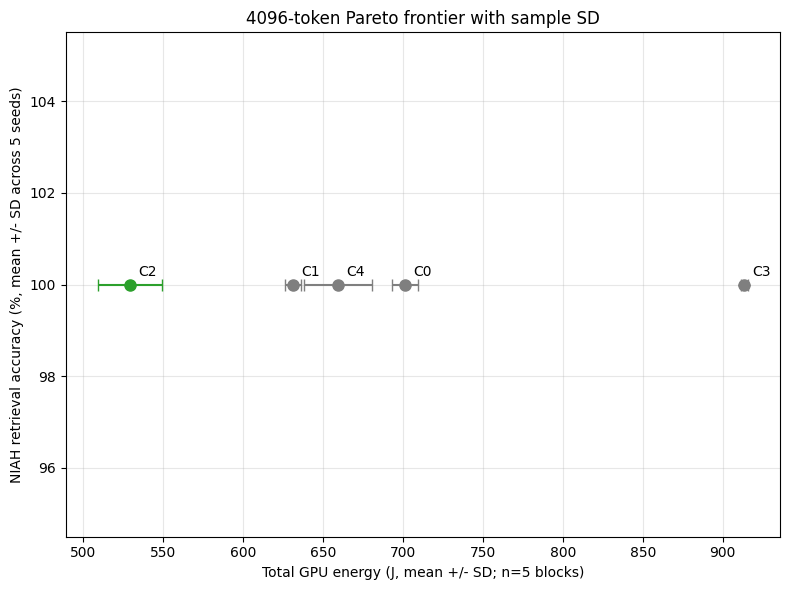

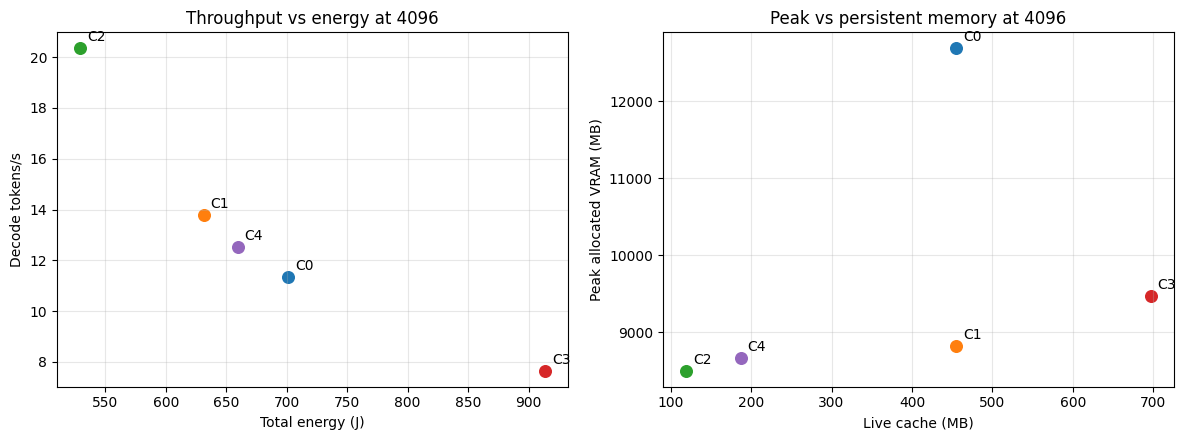

4096-token sensitivity summary


,energy_mean_j,energy_sd_j,accuracy_mean,accuracy_sd
variant,,,,
C2-B1024,529.299,20.016,100.000,0.000
C2-B1536,536.487,17.132,100.000,0.000
C2-B512,525.651,10.817,100.000,0.000
C3-TQ2,890.111,4.003,93.333,14.907
C3-TQ3,895.382,2.262,100.000,0.000
C3-TQ4,913.483,2.111,100.000,0.000


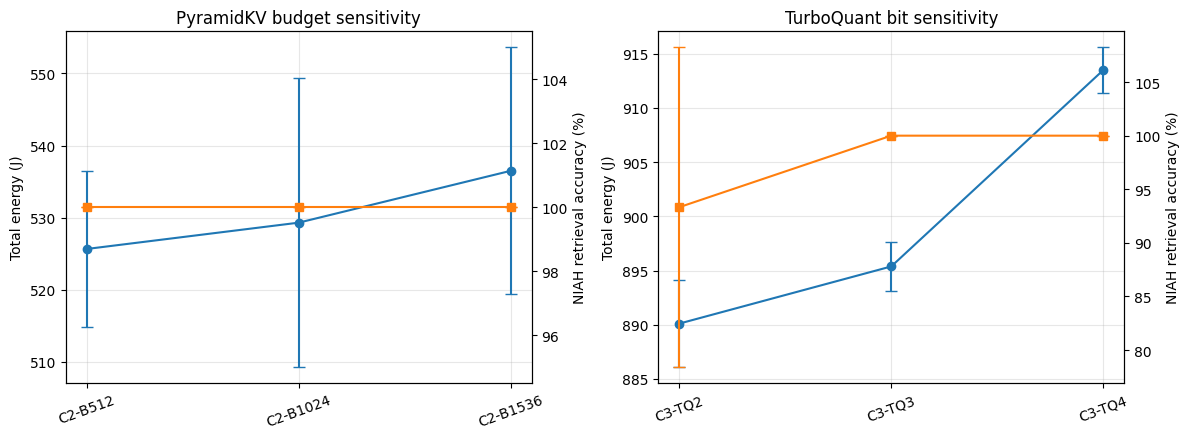

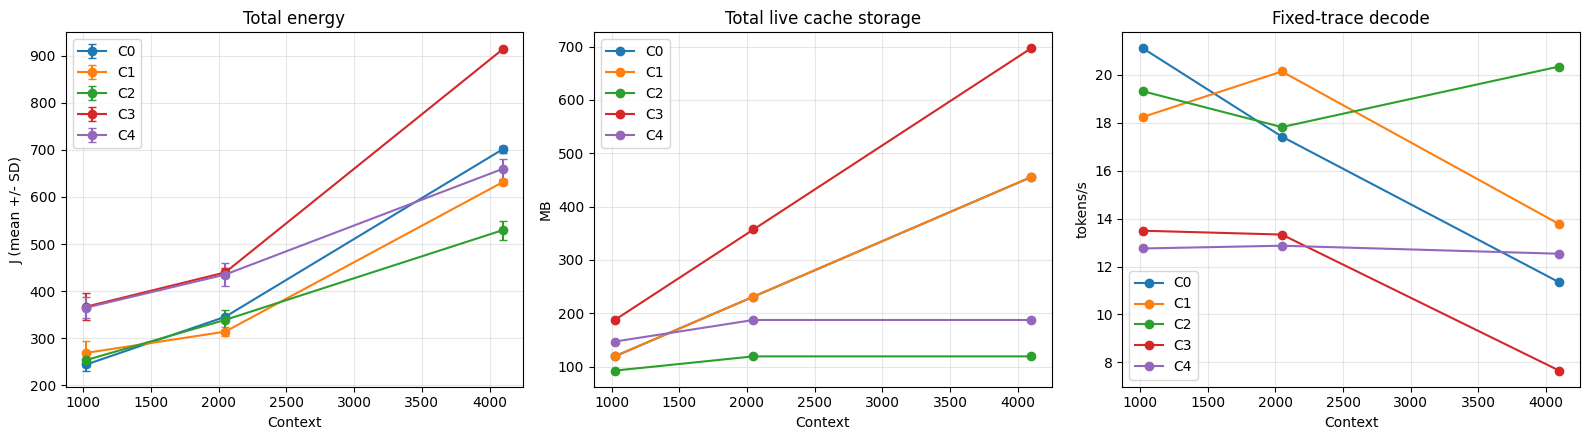

In [ ]:
def read_bool(series):
    if series.dtype == bool:
        return series
    normalized = series.astype(str).str.lower()
    assert normalized.isin(["true", "false"]).all(), sorted(normalized.unique())
    return normalized == "true"

def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    ranked = np.minimum(1.0, p_values[order] * (len(p_values) - np.arange(len(p_values))))
    ranked = np.maximum.accumulate(ranked)
    adjusted = np.empty(len(p_values))
    adjusted[order] = ranked
    return adjusted

def paired_test(frame, left, right, metric):
    pair = frame[frame.variant.isin([left, right])].pivot(
        index="block", columns="variant", values=metric,
    )[[left, right]].dropna()
    assert len(pair) == MEASURED_BLOCKS
    diff = pair[left] - pair[right]
    sd = float(diff.std(ddof=1))
    # Mean differences are the estimand; paired t-tests and t intervals are prespecified.
    statistic, p_value = stats.ttest_rel(pair[left], pair[right])
    effect = float(diff.mean() / sd) if sd else np.nan
    sem = stats.sem(diff)
    half = float(stats.t.ppf(0.975, len(diff) - 1) * sem) if sem else 0.0
    return {
        "comparison": f"{left}-{right}", "metric": metric,
        "n": len(diff), "test": "paired_t",
        "mean_difference_j": float(diff.mean()),
        "ci95_low_j": float(diff.mean() - half), "ci95_high_j": float(diff.mean() + half),
        "statistic": float(statistic), "p_unadjusted": float(p_value),
        "paired_d": effect,
    }

def validate_power_traces(frame):
    for row in frame.itertuples(index=False):
        path = Path(row.trace_file)
        assert path.exists(), path
        trace = json.loads(path.read_text())
        energies = []
        for phase in ["prefill", "decode"]:
            samples = trace[phase]
            times = np.asarray([x["elapsed_s"] for x in samples], dtype=float)
            powers = np.asarray([x["power_w"] for x in samples], dtype=float)
            assert len(times) >= 2 and np.all(np.diff(times) >= 0)
            if len(times) > 2:
                assert np.median(np.diff(times)) <= 0.25
            energies.append(float(np.trapezoid(powers, times)))
        assert np.isclose(sum(energies), row.total_energy_j, rtol=1e-9, atol=1e-6)

energy = pd.read_csv(ENERGY_CSV)
energy = energy[~read_bool(energy["warmup"])].copy()
quality = pd.read_csv(QUALITY_CSV)
sensitivity_energy = pd.read_csv(SENSITIVITY_ENERGY_CSV)
sensitivity_energy = sensitivity_energy[~read_bool(sensitivity_energy["warmup"])].copy()
sensitivity_quality = pd.read_csv(SENSITIVITY_QUALITY_CSV)
for frame in [energy, quality, sensitivity_energy, sensitivity_quality]:
    assert set(frame.fingerprint) == {EXPERIMENT_FINGERPRINT}
assert not energy.duplicated(["variant", "context", "block"]).any()
assert not quality.duplicated(["variant", "context", "depth", "seed"]).any()
assert not sensitivity_energy.duplicated(["variant", "context", "block"]).any()
assert not sensitivity_quality.duplicated(["variant", "context", "depth", "seed"]).any()
assert len(energy) == 5 * len(CONTEXTS) * MEASURED_BLOCKS
assert len(quality) == 5 * len(CONTEXTS) * len(DEPTHS) * len(list(QUALITY_SEEDS))
assert len(sensitivity_energy) == len(SENSITIVITY_CONDITIONS) * MEASURED_BLOCKS
assert len(sensitivity_quality) == len(SENSITIVITY_CONDITIONS) * len(DEPTHS) * len(list(QUALITY_SEEDS))
assert read_bool(energy["structural_pass"]).all()
assert read_bool(quality["structural_pass"]).all()
assert read_bool(sensitivity_energy["structural_pass"]).all()
assert read_bool(sensitivity_quality["structural_pass"]).all()
assert set(sensitivity_energy.variant) == {x["variant"] for x in SENSITIVITY_CONDITIONS}
validate_power_traces(energy)
validate_power_traces(sensitivity_energy)

summary = energy.groupby(["variant", "context"]).agg(
    total_energy_mean_j=("total_energy_j", "mean"),
    total_energy_sd_j=("total_energy_j", "std"),
    idle_adjusted_mean_j=("idle_adjusted_energy_j", "mean"),
    prefill_energy_mean_j=("prefill_energy_j", "mean"),
    decode_energy_mean_j=("decode_energy_j", "mean"),
    decode_tok_s=("decode_tok_s", "mean"),
    vram_peak_mb=("vram_peak_mb", "mean"),
    cache_live_mb=("post_decode_cache_live_bytes", lambda x: x.mean() / 2**20),
).reset_index()
summary.to_csv(SAVE_DIR / "v5_final_core_summary.csv", index=False)
print("Core energy summary")
display(summary.round(3))

quality["retrieval_correct"] = read_bool(quality["retrieval_correct"])
quality["format_correct"] = read_bool(quality["format_correct"])
accuracy = quality.groupby(["variant", "context", "depth"])[
    ["retrieval_correct", "format_correct"]
].mean().mul(100)
print("NIAH retrieval and exact-format accuracy (%)")
display(accuracy.round(1))

core_4096 = energy[energy.context == SENSITIVITY_CONTEXT]
contrasts = [("C1", "C2"), ("C1", "C3"), ("C1", "C4"),
             ("C2", "C4"), ("C3", "C4")]
test_metrics = ["total_energy_j", "decode_energy_j", "decode_s", "decode_tok_s"]
comparisons = [
    paired_test(core_4096, left, right, metric)
    for metric in test_metrics for left, right in contrasts
]
tests = pd.DataFrame(comparisons)
tests["p_holm"] = holm_adjust(tests.p_unadjusted)
tests.to_csv(SAVE_DIR / "v5_final_core_tests.csv", index=False)
print("Paired AWQ-path tests at 4096 (C0 is excluded by the split-plot design)")
display(tests.round(5))
interaction_rows = []
for metric in test_metrics:
    block_values = core_4096.pivot(index="block", columns="variant", values=metric)
    interaction = (block_values.C4 - block_values.C3) - (block_values.C2 - block_values.C1)
    statistic, p_value = stats.ttest_1samp(interaction, 0.0)
    half = float(stats.t.ppf(0.975, len(interaction) - 1) * stats.sem(interaction))
    interaction_rows.append({
        "metric": metric, "mean_difference_in_differences": interaction.mean(),
        "ci95_low": interaction.mean() - half, "ci95_high": interaction.mean() + half,
        "paired_t": statistic, "p_unadjusted": p_value,
    })
interaction_tests = pd.DataFrame(interaction_rows)
interaction_tests["p_holm"] = holm_adjust(interaction_tests.p_unadjusted)
interaction_tests.to_csv(SAVE_DIR / "v5_final_interaction_tests.csv", index=False)
print("PyramidKV x TurboQuant interaction: (C4-C3) - (C2-C1)")
display(interaction_tests.round(5))

energy_4096 = core_4096.groupby("variant").total_energy_j.agg(["mean", "std"])
seed_accuracy = quality[quality.context == SENSITIVITY_CONTEXT].groupby(
    ["variant", "seed"]
).retrieval_correct.mean().mul(100)
quality_4096 = seed_accuracy.groupby("variant").agg(["mean", "std"])
pareto = energy_4096.join(quality_4096, lsuffix="_energy", rsuffix="_accuracy")
pareto["pareto_optimal"] = True
for candidate in pareto.index:
    dominated = (
        (pareto.mean_energy <= pareto.loc[candidate, "mean_energy"])
        & (pareto.mean_accuracy >= pareto.loc[candidate, "mean_accuracy"])
        & ((pareto.mean_energy < pareto.loc[candidate, "mean_energy"])
           | (pareto.mean_accuracy > pareto.loc[candidate, "mean_accuracy"]))
    ).any()
    pareto.loc[candidate, "pareto_optimal"] = not dominated
pareto.to_csv(SAVE_DIR / "v5_final_pareto_4096.csv")
display(pareto.round(3))
multiobjective = core_4096.groupby("variant").agg(
    energy_j=("total_energy_j", "mean"), throughput_tok_s=("decode_tok_s", "mean"),
    live_cache_mb=("post_decode_cache_live_bytes", lambda x: x.mean() / 2**20),
    peak_vram_mb=("vram_peak_mb", "mean"),
).join(quality_4096[["mean"]].rename(columns={"mean": "retrieval_accuracy"}))
multiobjective["pareto_optimal"] = True
for candidate in multiobjective.index:
    dominated = (
        (multiobjective.energy_j <= multiobjective.loc[candidate, "energy_j"])
        & (multiobjective.live_cache_mb <= multiobjective.loc[candidate, "live_cache_mb"])
        & (multiobjective.throughput_tok_s >= multiobjective.loc[candidate, "throughput_tok_s"])
        & (multiobjective.retrieval_accuracy >= multiobjective.loc[candidate, "retrieval_accuracy"])
        & ((multiobjective.energy_j < multiobjective.loc[candidate, "energy_j"])
           | (multiobjective.live_cache_mb < multiobjective.loc[candidate, "live_cache_mb"])
           | (multiobjective.throughput_tok_s > multiobjective.loc[candidate, "throughput_tok_s"])
           | (multiobjective.retrieval_accuracy > multiobjective.loc[candidate, "retrieval_accuracy"]))
    ).any()
    multiobjective.loc[candidate, "pareto_optimal"] = not dominated
multiobjective.to_csv(SAVE_DIR / "v5_final_multiobjective_pareto_4096.csv")
print("Four-objective empirical mean frontier at 4096")
display(multiobjective.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
for config, row in pareto.iterrows():
    color = "tab:green" if row.pareto_optimal else "tab:gray"
    ax.errorbar(
        row.mean_energy, row.mean_accuracy, xerr=row.std_energy, yerr=row.std_accuracy,
        fmt="o", capsize=4, color=color, markersize=8, label=config,
    )
    ax.annotate(config, (row.mean_energy, row.mean_accuracy), xytext=(6, 6), textcoords="offset points")
front = pareto[pareto.pareto_optimal].sort_values("mean_energy")
ax.plot(front.mean_energy, front.mean_accuracy, "--", color="tab:green", alpha=0.7)
ax.set(
    title="4096-token Pareto frontier with sample SD",
    xlabel="Total GPU energy (J, mean +/- SD; n=5 blocks)",
    ylabel="NIAH retrieval accuracy (%, mean +/- SD across 5 seeds)",
)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(SAVE_DIR / "v5_final_pareto_uncertainty_4096.png", dpi=180, bbox_inches="tight")
plt.savefig(SAVE_DIR / "v5_final_pareto_uncertainty_4096.pdf", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for config, row in multiobjective.iterrows():
    axes[0].scatter(row.energy_j, row.throughput_tok_s, s=70)
    axes[0].annotate(config, (row.energy_j, row.throughput_tok_s), xytext=(5, 5), textcoords="offset points")
    axes[1].scatter(row.live_cache_mb, row.peak_vram_mb, s=70)
    axes[1].annotate(config, (row.live_cache_mb, row.peak_vram_mb), xytext=(5, 5), textcoords="offset points")
axes[0].set(title="Throughput vs energy at 4096", xlabel="Total energy (J)", ylabel="Decode tokens/s")
axes[1].set(title="Peak vs persistent memory at 4096", xlabel="Live cache (MB)", ylabel="Peak allocated VRAM (MB)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(SAVE_DIR / "v5_final_system_tradeoffs_4096.png", dpi=180, bbox_inches="tight")
plt.show()

base_energy = core_4096[core_4096.variant.isin(["C2", "C3"])].copy()
base_energy["variant"] = base_energy.variant.replace({"C2": "C2-B1024", "C3": "C3-TQ4"})
all_sensitivity_energy = pd.concat([sensitivity_energy, base_energy], ignore_index=True)
base_quality = quality[(quality.context == SENSITIVITY_CONTEXT) & quality.variant.isin(["C2", "C3"])].copy()
base_quality["variant"] = base_quality.variant.replace({"C2": "C2-B1024", "C3": "C3-TQ4"})
sensitivity_quality["retrieval_correct"] = read_bool(sensitivity_quality["retrieval_correct"])
all_sensitivity_quality = pd.concat([sensitivity_quality, base_quality], ignore_index=True)
sensitivity_seed_accuracy = all_sensitivity_quality.groupby(
    ["variant", "seed"]
).retrieval_correct.mean().mul(100)
sensitivity_summary = all_sensitivity_energy.groupby("variant").total_energy_j.agg(
    energy_mean_j="mean", energy_sd_j="std",
).join(
    sensitivity_seed_accuracy.groupby("variant").agg(
        accuracy_mean="mean", accuracy_sd="std",
    )
)
sensitivity_summary.to_csv(SAVE_DIR / "v5_final_sensitivity_summary_4096.csv")
print("4096-token sensitivity summary")
display(sensitivity_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, labels, title in [
    (axes[0], ["C2-B512", "C2-B1024", "C2-B1536"], "PyramidKV budget sensitivity"),
    (axes[1], ["C3-TQ2", "C3-TQ3", "C3-TQ4"], "TurboQuant bit sensitivity"),
]:
    plotted = sensitivity_summary.loc[labels]
    ax.errorbar(
        labels, plotted.energy_mean_j, yerr=plotted.energy_sd_j,
        marker="o", capsize=4, color="tab:blue", label="Energy",
    )
    quality_axis = ax.twinx()
    quality_axis.errorbar(
        labels, plotted.accuracy_mean, yerr=plotted.accuracy_sd,
        marker="s", capsize=4, color="tab:orange", label="Retrieval",
    )
    ax.set(title=title, ylabel="Total energy (J)")
    quality_axis.set_ylabel("NIAH retrieval accuracy (%)")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(SAVE_DIR / "v5_final_sensitivity_4096.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for config in ["C0", "C1", "C2", "C3", "C4"]:
    s = summary[summary.variant == config].sort_values("context")
    axes[0].errorbar(s.context, s.total_energy_mean_j, yerr=s.total_energy_sd_j, marker="o", capsize=3, label=config)
    axes[1].plot(s.context, s.cache_live_mb, "o-", label=config)
    axes[2].plot(s.context, s.decode_tok_s, "o-", label=config)
axes[0].set(title="Total energy", xlabel="Context", ylabel="J (mean +/- SD)")
axes[1].set(title="Total live cache storage", xlabel="Context", ylabel="MB")
axes[2].set(title="Fixed-trace decode", xlabel="Context", ylabel="tokens/s")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(SAVE_DIR / "v5_final_results.png", dpi=180, bbox_inches="tight")
plt.show()